# Phase 3: Vectorization, Broadcasting & Business Analytics
> **Target Audience:** Intermediate  
> **Prerequisites:** Phase 1 & Phase 2  
> **Key Goal:** Master multi-dimensional broadcasting, statistical aggregations across axes, and vector linear algebra.

Welcome to **Phase 3** of the NumPy Guide! Vectorization and broadcasting are the twin engines that give NumPy its expressive power and lightning execution speed.

### In this notebook, you will learn:
1. **The Mechanics of Vectorization** – Universal functions (`ufuncs`) vs explicit loops.
2. **The Golden Rules of Broadcasting** – How arrays of different shapes perform arithmetic.
3. **Statistical Aggregations & Axis Mechanics** – Deep dive into `axis=0` vs `axis=1`.
4. **Business Analytics Case Study** – Multi-year restaurant chain revenue analytics with Matplotlib visualizations.
5. **Linear Algebra & Vector Mathematics** – Dot products, Euclidean norms, and cosine similarity.
6. **Custom Universal Functions** – Applying `np.vectorize()` to arbitrary logic.

## 1. Vectorization & Mathematical Universal Functions (ufuncs)
NumPy ufuncs perform element-by-element operations at compiled C speed:

In [1]:
import numpy as np
import matplotlib.pyplot as plt

x = np.array([1.0, 4.0, 9.0, 16.0, 25.0])

print("Original array :", x)
print("Square root    :", np.sqrt(x))
print("Natural Log    :", np.log(x))
print("Exponential e^x:", np.exp(x))
print("Sine values    :", np.sin(x))

Original array : [ 1.  4.  9. 16. 25.]
Square root    : [1. 2. 3. 4. 5.]
Natural Log    : [0.         1.38629436 2.19722458 2.77258872 3.21887582]
Exponential e^x: [2.71828183e+00 5.45981500e+01 8.10308393e+03 8.88611052e+06
 7.20048993e+10]
Sine values    : [ 0.84147098 -0.7568025   0.41211849 -0.28790332 -0.13235175]


## 2. Demystifying Broadcasting Rules
Broadcasting describes how NumPy treats arrays with different shapes during arithmetic operations.

### The Two Rules of Broadcasting:
To determine compatibility, NumPy compares shapes element-wise starting from the **trailing (rightmost)** dimension:
1. Two dimensions are compatible if they are **equal**.
2. Two dimensions are compatible if **one of them is 1** (that dimension stretches to match).

```text
Matrix A:  (3, 4)
Vector B:     (4,)  --> treated as (1, 4)
Result  :  (3, 4)  --> Valid!
```

In [2]:
# Example 1: Scalar broadcast across matrix
matrix = np.ones((2, 3))
print("Matrix + 10 (Scalar broadcast):\n", matrix + 10)

# Example 2: 1D row vector broadcast across 2D matrix
row_vector = np.array([10, 20, 30])    # shape (3,)
print("\nMatrix + row_vector (shape (2, 3) + (3,)):\n", matrix + row_vector)

# Example 3: Column vector (3, 1) + Row vector (1, 4) -> Grid (3, 4)
col = np.array([[1], [2], [3]])        # shape (3, 1)
row = np.array([[10, 20, 30, 40]])     # shape (1, 4)
grid_sum = col + row
print("\nColumn (3, 1) + Row (1, 4) = Grid (3, 4):\n", grid_sum)

Matrix + 10 (Scalar broadcast):
 [[11. 11. 11.]
 [11. 11. 11.]]

Matrix + row_vector (shape (2, 3) + (3,)):
 [[11. 21. 31.]
 [11. 21. 31.]]

Column (3, 1) + Row (1, 4) = Grid (3, 4):
 [[11 21 31 41]
 [12 22 32 42]
 [13 23 33 43]]


### Fixing Broadcast Mismatches with `np.newaxis`
When shapes don't align, insert a new axis to enable broadcasting:

In [3]:
# A matrix of shape (3, 2)
mat = np.array([[1, 2], [3, 4], [5, 6]])
# A vector of 3 elements meant to scale each row
scale = np.array([10, 100, 1000])  # shape (3,)

# mat * scale directly would fail because shapes (3, 2) and (3,) cannot align!
# Using np.newaxis transforms shape from (3,) to (3, 1):
scale_col = scale[:, np.newaxis]
scaled_matrix = mat * scale_col

print("Scaled Matrix:\n", scaled_matrix)

Scaled Matrix:
 [[  10   20]
 [ 300  400]
 [5000 6000]]


## 3. Statistical Aggregations & Axis Mechanics
> **The Golden Mental Model:**
> `axis` specifies the dimension that gets **collapsed (aggregated away)**.
- `axis=0`: Collapses down the **rows** (computes per-column summary).
- `axis=1`: Collapses across the **columns** (computes per-row summary).

In [4]:
data_matrix = np.array([
    [10, 20, 30],
    [40, 50, 60]
])
print("Data Matrix:\n", data_matrix)

print(f"Total Sum            : {np.sum(data_matrix)}")
print(f"Column sums (axis=0) : {np.sum(data_matrix, axis=0)}")
print(f"Row sums    (axis=1) : {np.sum(data_matrix, axis=1)}")
print(f"Mean across columns  : {np.mean(data_matrix, axis=0)}")
print(f"Standard deviation   : {np.std(data_matrix):.2f}")
print(f"Min / Max values     : {np.min(data_matrix)} / {np.max(data_matrix)}")

Data Matrix:
 [[10 20 30]
 [40 50 60]]
Total Sum            : 210
Column sums (axis=0) : [50 70 90]
Row sums    (axis=1) : [ 60 150]
Mean across columns  : [25. 35. 45.]
Standard deviation   : 17.08
Min / Max values     : 10 / 60


### Cumulative Calculations
`np.cumsum()` computes cumulative sums, essential for time-series and running totals:

In [5]:
series = np.array([10, 20, 30, 40, 50])
print("Cumulative sum:", np.cumsum(series))

Cumulative sum: [ 10  30  60 100 150]


## 4. Case Study: Restaurant Chain Business Analytics
We analyze a multi-year dataset containing annual revenue across 5 popular dining chains:
- Data structure: `[chain_id, 2021, 2022, 2023, 2024]` (revenue in USD)

In [6]:
sales_data = np.array([
    [1, 150000, 180000, 220000, 250000],  # Paradise Biryani
    [2, 120000, 140000, 160000, 190000],  # Beijing Bites
    [3, 200000, 230000, 260000, 300000],  # Pizza Hub
    [4, 180000, 210000, 240000, 270000],  # Burger Point
    [5, 160000, 185000, 205000, 230000]   # Chai Point
])
chain_names = ['Paradise Biryani', 'Beijing Bites', 'Pizza Hub', 'Burger Point', 'Chai Point']
years = ['2021', '2022', '2023', '2024']

# Extract pure revenue numbers (excluding ID column)
revenues = sales_data[:, 1:]

# 1. Annual industry totals
annual_industry_totals = np.sum(revenues, axis=0)
print("Annual Industry Totals ($):")
for year, tot in zip(years, annual_industry_totals):
    print(f"  {year}: ${tot:,.0f}")

# 2. Average annual revenue per chain
chain_averages = np.mean(revenues, axis=1)
print("\nAverage Annual Revenue per Chain ($):")
for name, avg in zip(chain_names, chain_averages):
    print(f"  {name:18}: ${avg:,.0f}")

# 3. Monthly projected revenue (Vectorized division by 12)
monthly_projected = revenues / 12
print(f"\nProjected monthly revenue for {chain_names[0]} in 2024: ${monthly_projected[0, -1]:,.2f}")

Annual Industry Totals ($):
  2021: $810,000
  2022: $945,000
  2023: $1,085,000
  2024: $1,240,000

Average Annual Revenue per Chain ($):
  Paradise Biryani  : $200,000
  Beijing Bites     : $152,500
  Pizza Hub         : $247,500
  Burger Point      : $225,000
  Chai Point        : $195,000

Projected monthly revenue for Paradise Biryani in 2024: $20,833.33


### Visualizing Cumulative Revenue Growth Trajectories
We compute cumulative revenue across years for each chain and plot them:

<string>:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


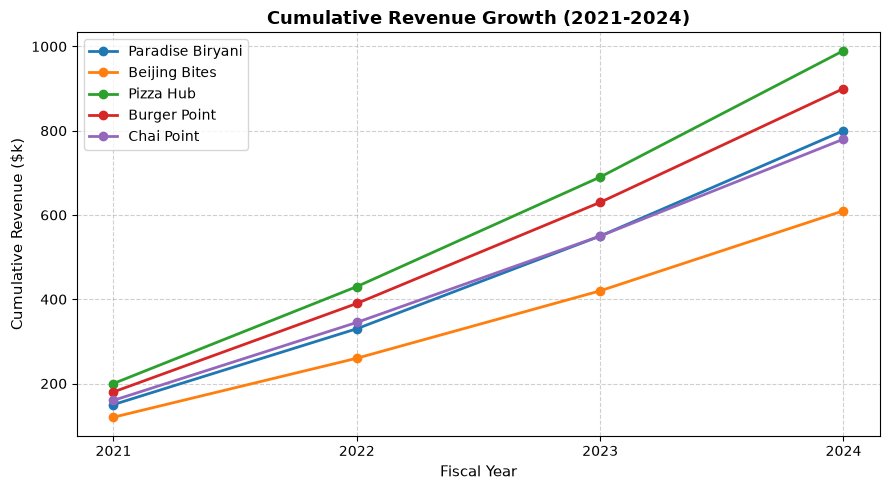

In [7]:
cumulative_revenue = np.cumsum(revenues, axis=1)

plt.figure(figsize=(9, 5))
for i, name in enumerate(chain_names):
    plt.plot(years, cumulative_revenue[i] / 1000, marker='o', linewidth=2, label=name)

plt.title("Cumulative Revenue Growth (2021-2024)", fontsize=13, fontweight='bold')
plt.xlabel("Fiscal Year", fontsize=11)
plt.ylabel("Cumulative Revenue ($k)", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

## 5. Linear Algebra & Vector Mathematics
Vector math forms the foundation of modern Machine Learning, Recommendation Systems, and NLP:

In [8]:
vec_a = np.array([1, 2, 3, 4, 5])
vec_b = np.array([6, 7, 8, 9, 10])

# Dot Product (Sum of element-wise products):
dot_product = np.dot(vec_a, vec_b)
print(f"Dot product (vec_a • vec_b) : {dot_product}")
print(f"Alternative (@ operator)    : {vec_a @ vec_b}")

# Vector Magnitude (Euclidean L2 Norm):
norm_a = np.linalg.norm(vec_a)
norm_b = np.linalg.norm(vec_b)
print(f"Length of vec_a (||vec_a||) : {norm_a:.4f}")

# Cosine Similarity: cos(theta) = (A • B) / (||A|| * ||B||)
cosine_sim = dot_product / (norm_a * norm_b)
angle_radians = np.arccos(np.clip(cosine_sim, -1.0, 1.0))
angle_degrees = np.degrees(angle_radians)

print(f"Cosine similarity           : {cosine_sim:.4f}")
print(f"Angle between vectors       : {angle_degrees:.2f} degrees")

Dot product (vec_a • vec_b) : 130
Alternative (@ operator)    : 130
Length of vec_a (||vec_a||) : 7.4162
Cosine similarity           : 0.9650
Angle between vectors       : 15.21 degrees


## 6. Custom Universal Functions (`np.vectorize`)
When native NumPy functions don't cover your custom logic, use `np.vectorize` to map Python functions across arrays:

In [9]:
categories = np.array(['biryani', 'chinese', 'pizza', 'burger', 'cafe'])

# Vectorize Python string transformation:
to_badge = np.vectorize(lambda x: f"[{x.upper()}-CERTIFIED]")
badge_labels = to_badge(categories)

print("Vectorized Custom Badges:\n", badge_labels)

Vectorized Custom Badges:
 ['[BIRYANI-CERTIFIED]' '[CHINESE-CERTIFIED]' '[PIZZA-CERTIFIED]'
 '[BURGER-CERTIFIED]' '[CAFE-CERTIFIED]']


## 7. Hands-On Practice Challenge
**Task:**
1. Given a 2D matrix of shape `(4, 3)`, normalize each column so that its mean is `0` and its standard deviation is `1` (Z-score standardization).
2. Verify that each column of the normalized matrix has approximately `mean = 0` and `std = 1`.

*Try coding your solution before checking below!*

In [10]:
# Solution:
np.random.seed(42)
raw_features = np.random.randint(10, 100, size=(4, 3)).astype(float)
print("Raw Features:\n", raw_features)

# Compute column-wise mean and std (axis=0)
col_means = np.mean(raw_features, axis=0)
col_stds = np.std(raw_features, axis=0)

# Broadcasting subtracts mean and divides by std across rows
z_standardized = (raw_features - col_means) / col_stds
print("\nZ-Score Standardized Matrix:\n", z_standardized)

print("\nVerifying Column Means (should be ~0):", np.round(np.mean(z_standardized, axis=0), 5))
print("Verifying Column Stds  (should be ~1):", np.round(np.std(z_standardized, axis=0), 5))

Raw Features:
 [[61. 24. 81.]
 [70. 30. 92.]
 [96. 84. 84.]
 [97. 33. 12.]]

Z-Score Standardized Matrix:
 [[-1.26364805 -0.7801081   0.42766929]
 [-0.69500643 -0.53047351  0.76980472]
 [ 0.94773604  1.71623782  0.52097895]
 [ 1.01091844 -0.40565621 -1.71845297]]

Verifying Column Means (should be ~0): [0. 0. 0.]
Verifying Column Stds  (should be ~1): [1. 1. 1.]


---
### Phase 3 Summary
- [x] Broadcasting aligns trailing dimensions; a dimension of size `1` stretches automatically.
- [x] Use `np.newaxis` to align incompatible dimensions.
- [x] `axis=0` aggregates down columns; `axis=1` aggregates across rows.
- [x] Vector dot product `np.dot(u, v)` or `u @ v`, norm `np.linalg.norm()`, and cosine similarity.
- [x] `np.vectorize()` wraps custom Python functions for array processing.

**Next Up:** Proceed to `phase-4.ipynb` to master file persistence, image processing as arrays, and memory optimization!